# Figure 2 — Cross-donor classification in PBMCs

Cohort composition (A), macro F1 under random cell-level splitting and donor-held-out cross-validation (B), site-covariate sensitivity (C), donor random-intercept correctness modeling (D), and training-donor ablation (E). Saved results show higher random-split macro F1 for all four representations.


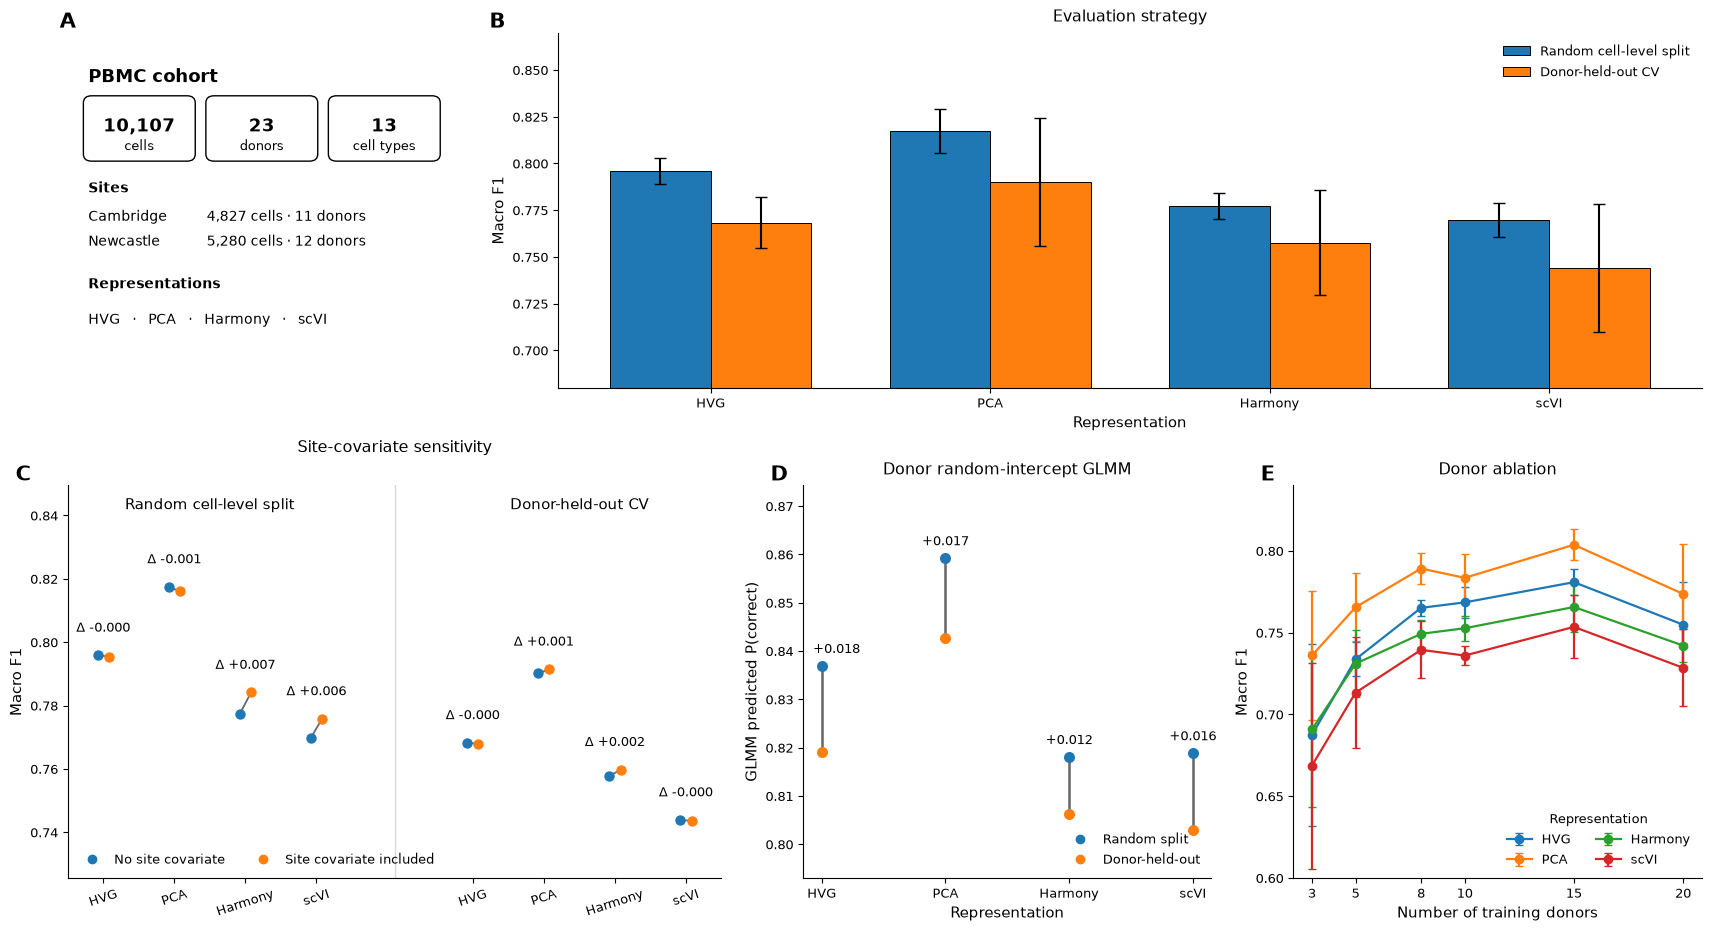

In [2]:

from pathlib import Path
import sys

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch

# ============================================================
# 1. Repository and data paths
# ============================================================

def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()
    for p in [start, *start.parents]:
        if (p / "src" / "scrna_benchmark").is_dir():
            return p
    raise RuntimeError("Run this notebook from somewhere inside the repository.")


REPO_ROOT = find_repo_root()

if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

ADATA_PATH = REPO_ROOT / "data/PBMC_Stephenson/stephenson_benchmark_ready.h5ad"
PRIMARY_DIR = REPO_ROOT / "results/pbmc_no_batch"
SITE_DIR = REPO_ROOT / "results/pbmc_with_site_covariate"

RANDOM_PATH = PRIMARY_DIR / "random_split/random_split_repeated_metrics.csv"
DONOR_PATH = PRIMARY_DIR / "donor_cv/metrics.csv"
SITE_RANDOM_PATH = SITE_DIR / "random_split/random_split_repeated_metrics.csv"
SITE_DONOR_PATH = SITE_DIR / "donor_cv/metrics.csv"
GLMM_PATH = PRIMARY_DIR / "mixed_models/correctness_glmm_predicted_probabilities.csv"
ABLATION_PATH = PRIMARY_DIR / "donor_ablation/donor_ablation_summary.csv"

required = [
    ADATA_PATH, RANDOM_PATH, DONOR_PATH,
    SITE_RANDOM_PATH, SITE_DONOR_PATH,
    GLMM_PATH, ABLATION_PATH,
]

missing = [p for p in required if not p.exists()]

if missing:
    raise FileNotFoundError(
        "Missing required Figure 2 inputs:\n"
        + "\n".join(str(p) for p in missing)
    )


# ============================================================
# 2. Cohort and numerical results
# ============================================================

adata = ad.read_h5ad(ADATA_PATH, backed="r")

n_cells = adata.n_obs
n_donors = adata.obs["patient_id"].astype(str).nunique()
n_cell_types = adata.obs["cell_type"].astype(str).nunique()

obs_summary = pd.DataFrame({
    "Site": adata.obs["Site"].astype(str),
    "patient_id": adata.obs["patient_id"].astype(str),
})

site_summary = (
    obs_summary
    .groupby("Site", observed=True)
    .agg(
        n_cells=("Site", "size"),
        n_donors=("patient_id", "nunique"),
    )
)

if hasattr(adata, "file") and adata.file is not None:
    adata.file.close()

random_df = pd.read_csv(RANDOM_PATH)
donor_df = pd.read_csv(DONOR_PATH)
site_random_df = pd.read_csv(SITE_RANDOM_PATH)
site_donor_df = pd.read_csv(SITE_DONOR_PATH)
glmm_df = pd.read_csv(GLMM_PATH)
ablation_df = pd.read_csv(ABLATION_PATH)

REP_ORDER = ["hvg", "pca", "harmony", "scvi"]

REP_LABELS = {
    "hvg": "HVG",
    "pca": "PCA",
    "harmony": "Harmony",
    "scvi": "scVI",
}

random_summary = (
    random_df
    .groupby("representation")["macro_f1"]
    .agg(["mean", "std"])
    .reindex(REP_ORDER)
)

donor_summary = (
    donor_df
    .set_index("representation")
    .reindex(REP_ORDER)
)

site_random_summary = (
    site_random_df
    .groupby("representation")["macro_f1"]
    .mean()
    .reindex(REP_ORDER)
)

site_donor_summary = (
    site_donor_df
    .set_index("representation")["macro_f1_mean"]
    .reindex(REP_ORDER)
)

random_delta = site_random_summary - random_summary["mean"]
donor_delta = site_donor_summary - donor_summary["macro_f1_mean"]

glmm_plot = glmm_df.copy()
glmm_plot["representation"] = glmm_plot["representation"].astype(str)
glmm_plot["scheme"] = glmm_plot["scheme"].astype(str)

scheme_rename = {
    "random": "Random split",
    "random_split": "Random split",
    "donor_held_out": "Donor-held-out",
    "donor-held-out": "Donor-held-out",
    "donor_cv": "Donor-held-out",
}

glmm_plot["scheme_clean"] = (
    glmm_plot["scheme"]
    .map(scheme_rename)
    .fillna(glmm_plot["scheme"])
)

glmm_wide = (
    glmm_plot
    .pivot(
        index="representation",
        columns="scheme_clean",
        values="pred_prob_correct",
    )
    .reindex(REP_ORDER)
)


# ============================================================
# 3. Styling 
# ============================================================

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.titlesize": 11.5,
    "axes.labelsize": 10.5,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 9.5,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

BLUE = "#1f77b4"
ORANGE = "#ff7f0e"
GRAY = "#666666"


def clean_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def panel_letter(ax, letter, x=-0.08, y=1.03):
    ax.text(
        x, y, letter,
        transform=ax.transAxes,
        fontsize=15,
        fontweight="bold",
        va="bottom",
        ha="left",
        clip_on=False,
    )


# ============================================================
# 4. Figure layout
#
#    A |                 B
#   --------------------------------
#          C       |   D   |   E
# ============================================================

fig = plt.figure(
    figsize=(17, 9.2),
    layout="constrained",
)

outer = fig.add_gridspec(
    2, 14,
    height_ratios=[0.95, 1.05],
)

axA = fig.add_subplot(outer[0, 0:4])
axB = fig.add_subplot(outer[0, 4:14])
axC = fig.add_subplot(outer[1, 0:6])
axD = fig.add_subplot(outer[1, 6:10])
axE = fig.add_subplot(outer[1, 10:14])


# ============================================================
# A. PBMC cohort overview
# ============================================================

panel_letter(axA, "A", x=-0.02, y=1.00)

axA.axis("off")
axA.set_xlim(0, 1)
axA.set_ylim(0, 1)

axA.text(
    0.05, 0.90, "PBMC cohort",
    fontsize=13,
    fontweight="bold",
    va="top",
)

stats = [
    (f"{n_cells:,}", "cells"),
    (f"{n_donors}", "donors"),
    (f"{n_cell_types}", "cell types"),
]

for x0, (big, small) in zip([0.05, 0.35, 0.65], stats):

    box = FancyBboxPatch(
        (x0, 0.65),
        0.25, 0.16,
        boxstyle="round,pad=0.012,rounding_size=0.02",
        linewidth=1.0,
        facecolor="white",
    )

    axA.add_patch(box)

    axA.text(
        x0 + 0.125, 0.735, big,
        ha="center",
        va="center",
        fontsize=13,
        fontweight="bold",
    )

    axA.text(
        x0 + 0.125, 0.680, small,
        ha="center",
        va="center",
        fontsize=9.5,
    )

axA.text(0.05, 0.55, "Sites", fontweight="bold")

if "Cambridge" in site_summary.index:
    row = site_summary.loc["Cambridge"]

    axA.text(0.05, 0.47, "Cambridge", fontsize=10)
    axA.text(
        0.34, 0.47,
        f"{int(row['n_cells']):,} cells · {int(row['n_donors'])} donors",
        fontsize=10,
    )

if "Ncl" in site_summary.index:
    row = site_summary.loc["Ncl"]

    axA.text(0.05, 0.40, "Newcastle", fontsize=10)
    axA.text(
        0.34, 0.40,
        f"{int(row['n_cells']):,} cells · {int(row['n_donors'])} donors",
        fontsize=10,
    )

axA.text(
    0.05, 0.28, "Representations",
    fontweight="bold",
)

axA.text(
    0.05, 0.18,
    "HVG   ·   PCA   ·   Harmony   ·   scVI",
    fontsize=10,
)


# ============================================================
# B. Evaluation strategy
# ============================================================

panel_letter(axB, "B", x=-0.06, y=1.00)

x = np.arange(len(REP_ORDER))
bar_width = 0.36

axB.bar(
    x - bar_width / 2,
    random_summary["mean"].to_numpy(),
    width=bar_width,
    yerr=random_summary["std"].to_numpy(),
    capsize=4,
    color=BLUE,
    edgecolor="black",
    linewidth=0.7,
    label="Random cell-level split",
)

axB.bar(
    x + bar_width / 2,
    donor_summary["macro_f1_mean"].to_numpy(),
    width=bar_width,
    yerr=donor_summary["macro_f1_std"].to_numpy(),
    capsize=4,
    color=ORANGE,
    edgecolor="black",
    linewidth=0.7,
    label="Donor-held-out CV",
)

axB.set_xticks(x, [REP_LABELS[r] for r in REP_ORDER])
axB.set_ylabel("Macro F1")
axB.set_xlabel("Representation")
axB.set_title("Evaluation strategy", pad=8)
axB.set_ylim(0.68, 0.87)

axB.legend(
    frameon=False,
    loc="upper right",
    fontsize=9.5,
)

clean_axis(axB)


# ============================================================
# C. Site-covariate sensitivity
# ============================================================

panel_letter(axC, "C", x=-0.08, y=1.00)

x_random = np.arange(len(REP_ORDER))
x_donor = np.arange(len(REP_ORDER)) + 5.2
dx = 0.08

c_ymin = (
    min(
        random_summary["mean"].min(),
        donor_summary["macro_f1_mean"].min(),
        site_random_summary.min(),
        site_donor_summary.min(),
    )
    - 0.018
)

c_ymax = (
    max(
        random_summary["mean"].max(),
        donor_summary["macro_f1_mean"].max(),
        site_random_summary.max(),
        site_donor_summary.max(),
    )
    + 0.032
)


def add_covariate_group(
    ax,
    positions,
    base_values,
    cov_values,
    deltas,
):
    for xpos, rep in zip(positions, REP_ORDER):

        y_base = base_values.loc[rep]
        y_cov = cov_values.loc[rep]

        # Paired connector
        ax.plot(
            [xpos - dx, xpos + dx],
            [y_base, y_cov],
            color=GRAY,
            linewidth=1.3,
            zorder=1,
        )

        # Without site covariate
        ax.scatter(
            xpos - dx, y_base,
            s=42,
            color=BLUE,
            zorder=3,
        )

        # With site covariate
        ax.scatter(
            xpos + dx, y_cov,
            s=42,
            color=ORANGE,
            zorder=3,
        )

        # Increased from 7.5 to 9
        delta = deltas.loc[rep]

        ax.text(
            xpos,
            max(y_base, y_cov) + 0.0065,
            f"Δ {delta:+.3f}",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="medium",
        )


add_covariate_group(
    axC,
    x_random,
    random_summary["mean"],
    site_random_summary,
    random_delta,
)

add_covariate_group(
    axC,
    x_donor,
    donor_summary["macro_f1_mean"],
    site_donor_summary,
    donor_delta,
)

axC.axvline(
    4.1,
    color="0.85",
    linewidth=1.0,
)

axC.set_xticks(
    np.concatenate([x_random, x_donor]),
    [REP_LABELS[r] for r in REP_ORDER] * 2,
    rotation=18,
)

axC.set_ylim(c_ymin, c_ymax)
axC.set_ylabel("Macro F1")
axC.set_title("Site-covariate sensitivity", pad=24)

axC.text(
    np.mean(x_random),
    c_ymax - 0.004,
    "Random cell-level split",
    ha="center",
    va="top",
    fontsize=10.5,
)

axC.text(
    np.mean(x_donor),
    c_ymax - 0.004,
    "Donor-held-out CV",
    ha="center",
    va="top",
    fontsize=10.5,
)

handles_C = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        color=BLUE,
        markersize=6,
        label="No site covariate",
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        color=ORANGE,
        markersize=6,
        label="Site covariate included",
    ),
]

axC.legend(
    handles=handles_C,
    frameon=False,
    loc="lower left",
    ncol=2,
    fontsize=9,
)

clean_axis(axC)


# ============================================================
# D. Donor random-intercept GLMM
# ============================================================

panel_letter(axD, "D", x=-0.08, y=1.00)

xpos = np.arange(len(REP_ORDER))

for i, rep in enumerate(REP_ORDER):

    donor_val = glmm_wide.loc[rep, "Donor-held-out"]
    random_val = glmm_wide.loc[rep, "Random split"]

    axD.plot(
        [i, i],
        [donor_val, random_val],
        color=GRAY,
        linewidth=1.8,
        zorder=1,
    )

    axD.scatter(
        i, random_val,
        s=48,
        color=BLUE,
        zorder=3,
    )

    axD.scatter(
        i, donor_val,
        s=48,
        color=ORANGE,
        zorder=3,
    )

    delta = random_val - donor_val

    axD.text(
        i + (0.12 if i == 0 else 0),
        max(random_val, donor_val) + 0.002,
        f"+{delta:.3f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

axD.set_xticks(
    xpos,
    [REP_LABELS[r] for r in REP_ORDER],
)

axD.set_xlabel("Representation")
axD.set_ylabel("GLMM predicted P(correct)")
axD.set_title("Donor random-intercept GLMM", pad=8)

glmm_min = glmm_wide.min().min()
glmm_max = glmm_wide.max().max()

axD.set_ylim(
    glmm_min - 0.01,
    glmm_max + 0.015,
)

handles_D = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        color=BLUE,
        markersize=6,
        label="Random split",
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        color=ORANGE,
        markersize=6,
        label="Donor-held-out",
    ),
]

axD.legend(
    handles=handles_D,
    frameon=False,
    loc="lower right",
    fontsize=9,
)

clean_axis(axD)


# ============================================================
# E. Donor ablation
# ============================================================

panel_letter(axE, "E", x=-0.08, y=1.00)

for rep in REP_ORDER:

    sub = (
        ablation_df[
            ablation_df["representation"].eq(rep)
        ]
        .sort_values("k_train_donors")
    )

    axE.errorbar(
        sub["k_train_donors"],
        sub["macro_f1_mean"],
        yerr=sub["macro_f1_std"],
        marker="o",
        linewidth=1.6,
        capsize=3,
        label=REP_LABELS[rep],
    )

axE.set_xlabel("Number of training donors")
axE.set_ylabel("Macro F1")
axE.set_title("Donor ablation", pad=8)

axE.set_xticks(
    sorted(ablation_df["k_train_donors"].unique())
)

axE.set_ylim(0.60, 0.84)

axE.legend(
    frameon=False,
    ncol=2,
    fontsize=9,
    title="Representation",
    title_fontsize=9,
    loc="lower right",
)

clean_axis(axE)


# ============================================================
# 5. Export: PNG + TIFF (350 DPI)
# ============================================================

_export_dir = REPO_ROOT / "figures" / "main"
_export_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    _export_dir / "figure2_pbmc.png",
    dpi=350,
    bbox_inches="tight",
)

fig.savefig(
    _export_dir / "figure2_pbmc.tif",
    dpi=350,
    bbox_inches="tight",
    pil_kwargs={"compression": "tiff_lzw"},
)

plt.show()
